# Stellarator design for people who train models

A stellarator uses a twisted magnetic field to confine a plasma. Changing its shape changes how the field lines wind and how particles drift. The design problem is to find shapes with useful properties, subject to physics and engineering constraints.

Here is a small problem you can run and modify: **six shape parameters, a physics solver, and a few scalar outputs.** We build a surrogate, acquire new training data, differentiate through the solver, and finally optimize quasisymmetry with a growing set of shape parameters. No plasma-physics background is assumed.

The opportunity resembles what attracted ML researchers to molecular structure: a useful representation, reliable labels, and a demanding inverse problem. Here we choose a boundary to obtain desired field properties. These examples address a vacuum magnetic configuration; they do not predict fusion power or design the coils.

**Route:** [Data](#1.-Learn-from-a-database) · [Gradients](#2.-Differentiate-through-the-physics) · [QA design](#3.-Build-a-quasi-axisymmetric-configuration-from-a-simple-seed) · [Smooth paths](#4.-Inspect-the-objective,-not-just-the-training-curve) · [Finite-beta QI](#5.-A-costly-objective-with-competing-basins). The last two sections are longer experiments; their saved outputs can be read without rerunning them.

## Run against VMEX main

This notebook uses the public API on `main`. Install an editable checkout with Python 3.11 or newer:

```bash
git clone https://github.com/uwplasma/VMEX.git
cd VMEX
git switch main
python -m pip install -e ".[optimizers]" jupyter
jupyter notebook /path/to/stellarator_optimization.ipynb
```

Run the cells in order. CPU is sufficient; allow several minutes for the introductory sections. The finite-beta QI study adds several minutes and another adjoint compilation. The notebook uses 64-bit arithmetic and saves a database in `results/ml_notebook/`. All experiments and plotting helpers are included below; the saved figures can also be read without running anything.

In [1]:
from pathlib import Path
from time import perf_counter
from io import BytesIO
from dataclasses import replace
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from scipy.optimize import minimize, minimize_scalar, least_squares
from scipy.interpolate import RBFInterpolator
from scipy.stats import qmc
from IPython.display import Image, display
import vmex as vj
from vmex import optimize as opt
from vmex.core.qi import ConstructedQIResidual
from vmex.core.plotting import plot_boundary_3d, surface_rz

jax.config.update("jax_enable_x64", True)
REPO = Path(vj.__file__).resolve().parents[1]
OUTPUT = REPO / "results/ml_notebook"
OUTPUT.mkdir(parents=True, exist_ok=True)

In [2]:
DOF_NAMES = ["RBC(0,1)", "ZBS(0,1)", "RBC(1,0)", "ZBS(1,0)", "RBC(1,1)", "ZBS(1,1)"]
STEP = 0.05                       # metres per normalized parameter
TARGETS = np.array([0.45, 5.0])    # mean iota, aspect ratio
SCALES = np.array([0.05, 0.5])     # loss preferences, not error bars
NS, MPOL, NTOR, FTOL = 21, 5, 5, 1e-12
SOBOL_POWER, RANDOM_SEED = 6, 42   # 64 samples plus the seed
ADAM_STEPS, LEARNING_RATE = 50, 0.08
ACTIVE_ROUNDS, MULTISTART, LBFGS_STEPS = 3, 4, 20
SURFACES = (0.25, 0.5, 0.75)
LABEL_NAMES = ["mean_iota", "aspect_ratio", "qs_qa_total", "magnetic_well"]
qs = opt.QuasisymmetryRatioResidual(SURFACES, helicity_m=1, helicity_n=0)

seed = vj.VmecInput.from_file(REPO / "examples/data/input.LandremanPaul2021_QA_lowres")
seed = replace(seed, lfreeb=False, pres_scale=0.0, ncurr=1, curtor=0.0,
               ac=np.zeros_like(seed.ac), delt=0.5, ns_array=np.array([NS]),
               ftol_array=np.array([FTOL]), niter_array=np.array([5000]))
seed = seed.change_resolution(mpol=MPOL, ntor=NTOR, ntheta=2*MPOL+6, nzeta=2*NTOR+4)


### Plotting helpers · optional to read

The collapsed cells below format figures using VMEX's geometry and plotting API. The experiment cells keep the parameters, loss and optimizer visible.

In [3]:
TEAL, ORANGE = "#007F86", "#DC7046"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#FAFBFC", "figure.facecolor": "white"})


def show_figure(fig):
    """Embed a PNG even after VMEX selects Matplotlib's file-writing backend."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


def show_sections(equilibria, labels):
    """Overlay VMEX boundaries at three toroidal cuts."""
    theta = np.linspace(0, 2*np.pi, 160)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
    extents = []
    for ax, fraction in zip(axes, (0, .25, .5)):
        for eq, label, color, style in zip(equilibria, labels, (TEAL, ORANGE), ("-", "--")):
            wout = eq.wout
            r, z = surface_rz(wout, s_index=wout.ns-1, theta=theta,
                              phi=np.array([fraction*2*np.pi/wout.nfp]))
            ax.plot(r[:, 0], z[:, 0], label=label, color=color, ls=style, lw=2)
            extents.append([r.min(), r.max(), z.min(), z.max()])
        ax.set(xlabel="R [m]", ylabel="Z [m]", aspect="equal",
               title=rf"$\phi/(2\pi/N_{{fp}})={fraction:g}$")
        ax.grid(alpha=.15)
    extents = np.asarray(extents)
    rlo, rhi = extents[:, 0].min(), extents[:, 1].max()
    zlo, zhi = extents[:, 2].min(), extents[:, 3].max()
    pad = .04*max(rhi-rlo, zhi-zlo)
    for ax in axes:
        ax.set(xlim=(rlo-pad, rhi+pad), ylim=(zlo-pad, zhi+pad))
    axes[0].legend(loc="upper left", frameon=False, fontsize=8)
    show_figure(fig)


def show_predictions(truth, predicted, baseline):
    """Show held-out errors against a training-mean predictor."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
    for j, (ax, name) in enumerate(zip(axes, ("Mean iota", "Aspect ratio"))):
        a, b = truth[:, j], predicted[:, j]
        limits = [min(a.min(), b.min()), max(a.max(), b.max())]
        ax.plot(limits, limits, "--", color="0.65")
        ax.scatter(a, b, color=TEAL, s=35, edgecolor="white", zorder=3)
        rmse = np.sqrt(np.mean((a-b)**2))
        reference = np.sqrt(np.mean((a-baseline[j])**2))
        ax.set(xlabel="VMEX held-out value", ylabel="Prediction", title=name)
        ax.text(.04, .96, f"RMSE {rmse:.2g}\nMean baseline {reference:.2g}",
                va="top", transform=ax.transAxes, fontsize=9)
    show_figure(fig)


def show_training(losses, values):
    """Keep the objective and its physical outputs beside one another."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained")
    for ax, series, name in zip(axes, (losses, values[:, 0], values[:, 1]),
                                ("Loss", "Mean iota", "Aspect ratio")):
        ax.plot(series, ".-", color=TEAL)
        ax.set(xlabel="Adam step", ylabel=name, title=name)
        ax.grid(alpha=.15)
    for ax, target in zip(axes[1:], TARGETS):
        ax.axhline(target, color=ORANGE, ls="--", label="Target")
        ax.legend(frameon=False, fontsize=9)
    show_figure(fig)


def show_verification(coarse, refined):
    """Compare independently solved endpoints on two radial grids."""
    fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
    for offset, values, color, label in ((-.18, coarse, TEAL, f"ns={NS}"),
                                       (.18, refined, ORANGE, f"ns={2*NS-1}")):
        ax.bar(np.arange(2)+offset, values, width=.36, color=color, label=label)
    ax.set(xticks=[0, 1], xticklabels=["Initial", "Selected"], ylabel="True loss",
           title="Independent resolution check")
    ax.legend(frameon=False)
    show_figure(fig)

In [4]:
def show_qa_boozer(equilibria):
    theta, zeta = np.meshgrid(np.linspace(0, 2*np.pi, 100),
                              np.linspace(0, 2*np.pi/equilibria[0].inp.nfp, 100), indexing="ij")
    fields, surfaces = [], []
    for eq in equilibria:
        b = opt.boozer_modes_from_wout(eq.wout, surfaces=(0.5,), mboz=12, nboz=12)
        phase = theta[..., None]*b["xm_b"] - zeta[..., None]*b["xn_b"]
        strength = np.sum(b["bmnc_b"][0]*np.cos(phase)+b["bmns_b"][0]*np.sin(phase), axis=-1)
        b00 = b["bmnc_b"][0][(b["xm_b"] == 0) & (b["xn_b"] == 0)][0]
        fields.append(strength/b00)
        surfaces.append(float(b["s_b"][0]))
    levels = np.linspace(min(a.min() for a in fields), max(a.max() for a in fields), 18)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    for ax, field, title, s in zip(axes, fields, ("Seed", "QA-optimized"), surfaces):
        image = ax.contourf(zeta/np.pi, theta/np.pi, field, levels=levels, cmap="viridis")
        ax.contour(zeta/np.pi, theta/np.pi, field, levels=levels, colors="white", linewidths=.5, alpha=.6)
        ax.set(xlabel="Boozer toroidal angle / π", ylabel="Boozer poloidal angle / π",
               title=f"{title}: |B|/B₀₀ at s={s:.4f}")
    fig.colorbar(image, ax=axes, label="|B| / B₀₀", shrink=.85)
    show_figure(fig)

In [5]:
def show_3d_pair(equilibria, labels, name):
    """Use VMEX's full-torus renderer with its standard view for both endpoints."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for index, (ax, eq, label) in enumerate(zip(axes, equilibria, labels)):
        path = plot_boundary_3d(eq.wout, OUTPUT / f"{name}_{index}.png", ntheta=100, nzeta=240)
        ax.imshow(plt.imread(path))
        ax.set_title(label)
        ax.set_axis_off()
    show_figure(fig)

In [6]:
def show_hard_search(t, values, accepted, endpoints, verified):
    """Separate measured branches and show accepted local-search steps."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
    for mask in (t < 0, t > 0):
        axes[0].semilogy(t[mask], values[mask, 0], "o-", color="0.35", markersize=3)
    axes[0].axvspan(-0.6, 0.6, color="0.9", label="Central interval not resolved")
    accepted = np.asarray(accepted)
    for j, color in enumerate((ORANGE, TEAL)):
        steps = accepted[accepted[:, 0] == j]
        axes[0].scatter(endpoints[j], verified[j, 0], color=color, s=80, marker="*", zorder=4)
        axes[1].plot(np.arange(len(steps)), steps[:, 2], ".-", color=color, label=f"Start {HARD_STARTS[j]:+.1f}")
    axes[0].set(xlabel="Collective boundary parameter t", ylabel="Independent combined loss", title="Two sampled basins")
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].set(xlabel="Accepted step", ylabel="Combined loss", title="Same optimizer, different starts")
    axes[1].legend(frameon=False)
    for ax in axes:
        ax.grid(alpha=.15)
    show_figure(fig)


def show_hard_refinement(offsets, values):
    """Compare QI grids on the same independently solved equilibria."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), layout="constrained")
    for j, ax in enumerate(axes):
        ax.plot(offsets, values[j, :, 0]-values[j, len(offsets)//2, 0], "o-", color=ORANGE, label="Optimization QI grid")
        ax.plot(offsets, values[j, :, 1]-values[j, len(offsets)//2, 1], "s-", color=TEAL, label="Finer QI grid")
        ax.axvline(0, color="0.6", ls=":")
        ax.set(xticks=offsets[::2], xlabel="Offset from selected t", ylabel="Change from score at selected t", title=f"Start {HARD_STARTS[j]:+.1f}")
        ax.grid(alpha=.15); ax.legend(frameon=False, fontsize=8)
    show_figure(fig)

## What are the trainable parameters?

We prescribe the outermost magnetic surface. VMEX solves for the nested surfaces and magnetic field inside it. For a stellarator-symmetric boundary,

$$
R(\theta,\phi)=\sum_{m,n}R_{mn}\cos(m\theta-nN_{\rm fp}\phi),\qquad
Z(\theta,\phi)=\sum_{m,n}Z_{mn}\sin(m\theta-nN_{\rm fp}\phi).
$$

Here $R$ is distance from the central vertical axis, $Z$ is height, $\theta$ goes around the tube, and $\phi$ goes around the machine. $N_{\rm fp}=2$ repeats the shape twice per turn. The input names are `RBC(n,m)` and `ZBS(n,m)`; their index order is **n, m**.

We start near the [Landreman–Paul quasi-axisymmetric configuration](https://doi.org/10.1103/PhysRevLett.128.035001). Six coefficients can move by up to 5 cm: $c_j=c_{j,0}+0.05x_j$, with $x_j\in[-1,1]$. The major-radius coefficient, toroidal flux, field-period count, pressure, and current stay fixed. Pressure and current are zero. This makes iota an output of the geometry, rather than a prescribed profile.

VMEX handles the coefficient indexing through `VmecProblem.subproblem` and `input_from_x`; we do not implement that mapping ourselves. This range permits a visible change in compactness. Six coefficients still span only one restricted design family. Later we start from a different configuration and release more Fourier modes.

In [7]:
def physical_labels(state, runtime):
    """Return iota, aspect, QA residual and magnetic well in that order."""
    return jnp.array([opt.mean_iota(state, runtime), opt.aspect_ratio(state, runtime),
                      qs.total_state(state, runtime), opt.magnetic_well(state, runtime)])


def physical_loss(state, runtime):
    """Two target penalties, evaluated on the solved equilibrium."""
    values = jnp.array([opt.mean_iota(state, runtime), opt.aspect_ratio(state, runtime)])
    return 0.5*jnp.sum(((values-TARGETS)/SCALES)**2)

In [8]:
problem = opt.VmecProblem.from_loss(seed, physical_loss, max_mode=1,
                                   use_ess=False, progress=True).subproblem(active=DOF_NAMES)
x_seed = np.asarray(problem.x0)


def solve(x, ns=NS):
    """Independently solve a normalized boundary vector; reject failed solves."""
    inp = replace(problem.input_from_x(x_seed+STEP*np.asarray(x)), ns_array=np.array([ns]))
    return opt.solve_equilibrium(inp, raise_on_max_iterations=True)


initial = solve(np.zeros(len(DOF_NAMES)))
print("Trainable coefficients:", ", ".join(problem.dof_names))

Building VMEX problem...


VMEX problem ready in 3.2 s.


Trainable coefficients: RBC(0,1), ZBS(0,1), RBC(1,0), ZBS(1,0), RBC(1,1), ZBS(1,1)


In [9]:
def observe(x):
    """Keep failed evaluations as missing labels with an explicit reason."""
    try:
        eq = solve(x)
        labels = np.asarray(physical_labels(eq.state, eq.runtime))
        if not np.isfinite(labels).all():
            raise ValueError("Non-finite physical label")
        return labels, ""
    except (vj.VmecError, RuntimeError, ValueError) as error:
        return np.full(4, np.nan), str(error)

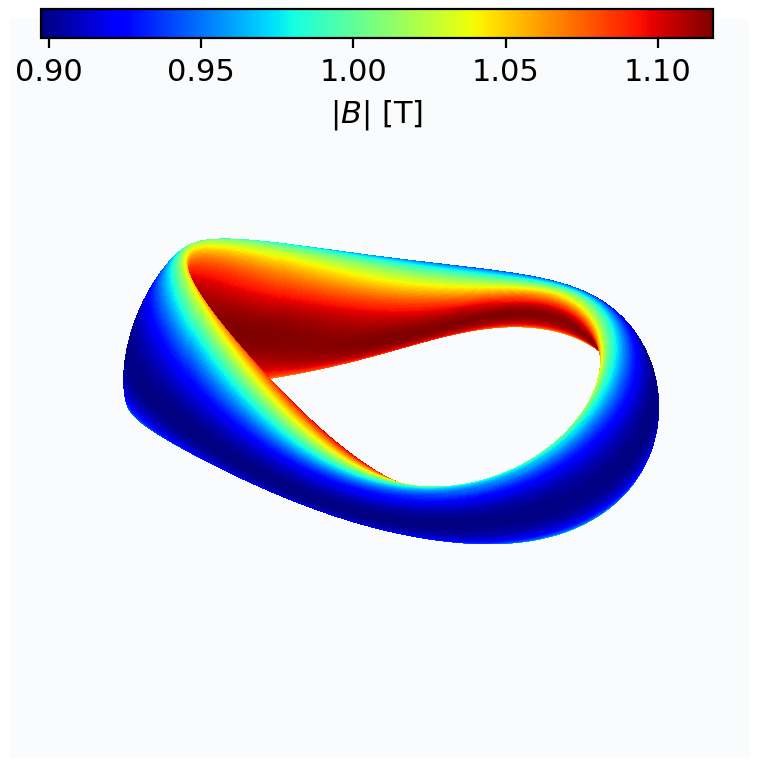

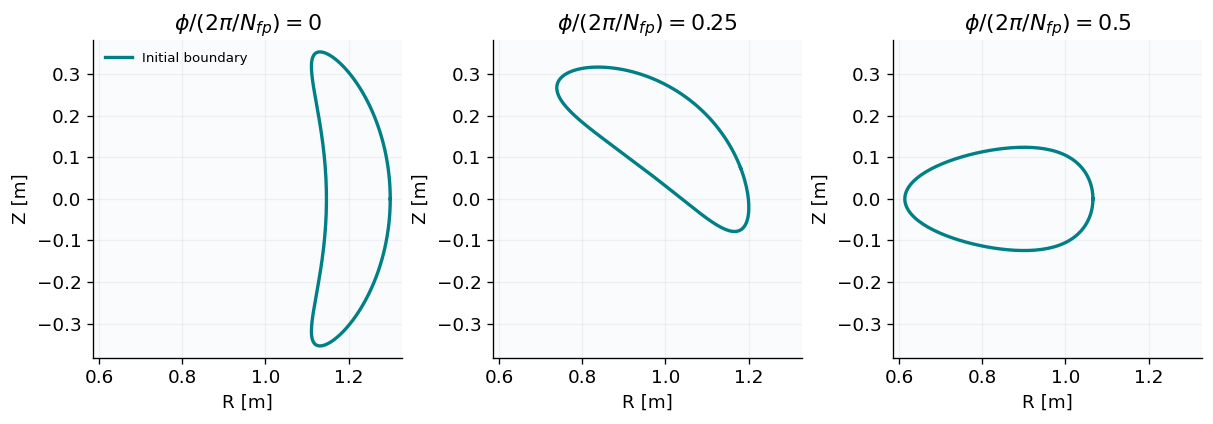

In [10]:
display(Image(filename=str(plot_boundary_3d(initial.wout, OUTPUT / "boundary.png")), width=620))
show_sections([initial], ["Initial boundary"])

**Try one degree of freedom.** Choose a coefficient below and move it by one normalized unit. The dashed boundary moves by 5 cm in one Fourier coefficient; the field inside is re-solved. The full optimizer will vary all six together.

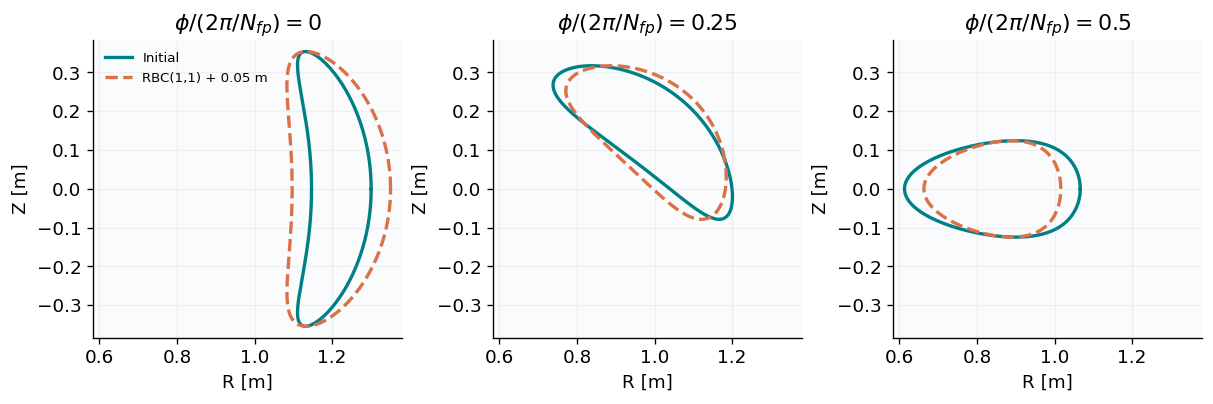

In [11]:
MODE = 4                         # RBC(1,1); choose 0 through 5
AMPLITUDE = 1.0                  # normalized units
x_trial = np.zeros(len(DOF_NAMES))
x_trial[MODE] = AMPLITUDE
trial = solve(x_trial)
show_sections([initial, trial], ["Initial", f"{DOF_NAMES[MODE]} + {STEP*AMPLITUDE:g} m"])

## What comes back from the solver?

The input vector describes a boundary; the output vector describes a magnetic configuration. Keep the physical labels separate from the loss used to select a design.

| Output | Meaning | How to use it |
|---|---|---|
| Mean iota, $\bar\iota$ | Mean poloidal winding per toroidal turn; signed arithmetic mean on the half radial mesh | Match a target; a mean alone does not prevent low-iota surfaces |
| Aspect ratio, $A$ | Major radius divided by effective minor radius | Keep a desired compactness |
| Quasisymmetry (QS) residual | Departure from a symmetry of field strength in Boozer magnetic coordinates; here quasi-axisymmetry | Smaller is better for this symmetry target |
| Constructed QI residual | Departure from a constructed quasi-isodynamic field, with poloidally closed strength contours and vanishing orbit-averaged radial drift in the ideal limit | Alternative confinement objective to QS |
| $\Gamma_c$ | Bounce-averaged fast-particle drift-alignment proxy | Smaller is favorable; it is not a lost-particle fraction |
| Mapped pwO residual | Field-strength variation across a specified piecewise-omnigenous construction | A construction proxy; a small residual does not certify piecewise omnigenity or confinement |
| $\epsilon_{\rm eff}^{3/2}$ | Effective-ripple measure entering neoclassical transport in the $1/\nu$ regime | Report the exponent; it is not total plasma transport |
| Magnetic well | $(V'(0)-V'(1))/V'(0)$, with $V'=dV/ds$ and $V$ the enclosed volume | Positive is favorable; this is not a finite-pressure stability certificate |

Boozer angles differ from the boundary angles above; QS is a symmetry of field strength, not of the geometric surface. Here $s$ is toroidal flux divided by its boundary value, from 0 on axis to 1 at the boundary. Surface selection, spatial resolution, and diagnostic quadrature are part of a label's definition. We compute the four inexpensive labels below. Failed solves and unavailable labels are retained as missing values with error information.

QS, QI, and pwO describe different design strategies. We do not minimize every row at once. The default teaching loss is simply

$$
L=\frac12\left(\frac{\bar\iota-0.45}{0.05}\right)^2+
\frac12\left(\frac{A-5}{0.5}\right)^2.
$$

This loss does not penalize QS or magnetic well; improving it can worsen confinement-related metrics. The denominators express preferences, not measurement uncertainty. Changing them changes the design problem.

## 1. Learn from a database

We use four labels and a radial-basis surrogate. Every configuration is solved independently. Failed samples remain NaN, with their reason recorded; they never become training labels. The larger shape range makes this a nonlinear regression problem, even with only six inputs.

In [12]:
X = np.vstack([np.zeros(len(DOF_NAMES)),
               2*qmc.Sobol(len(DOF_NAMES), scramble=True, seed=RANDOM_SEED).random_base2(SOBOL_POWER)-1])
Y, errors = np.full((len(X), 4), np.nan), [""]*len(X)
for i, x in enumerate(X):
    Y[i], errors[i] = observe(x)
    if (i+1) % 16 == 0 or i+1 == len(X):
        print(f"Evaluated {i+1}/{len(X)} boundaries")
valid = np.isfinite(Y).all(axis=1)
print(f"Usable samples: {valid.sum()}/{len(X)}")

Evaluated 16/65 boundaries


Evaluated 32/65 boundaries


Evaluated 48/65 boundaries


Evaluated 64/65 boundaries


Evaluated 65/65 boundaries
Usable samples: 59/65


Keep the test rows out of training and normalization. This split measures interpolation near one seed. A larger study should also hold out whole stellarator families or optimization trajectories. The surrogate below is a baseline to replace, not a proposed best model.

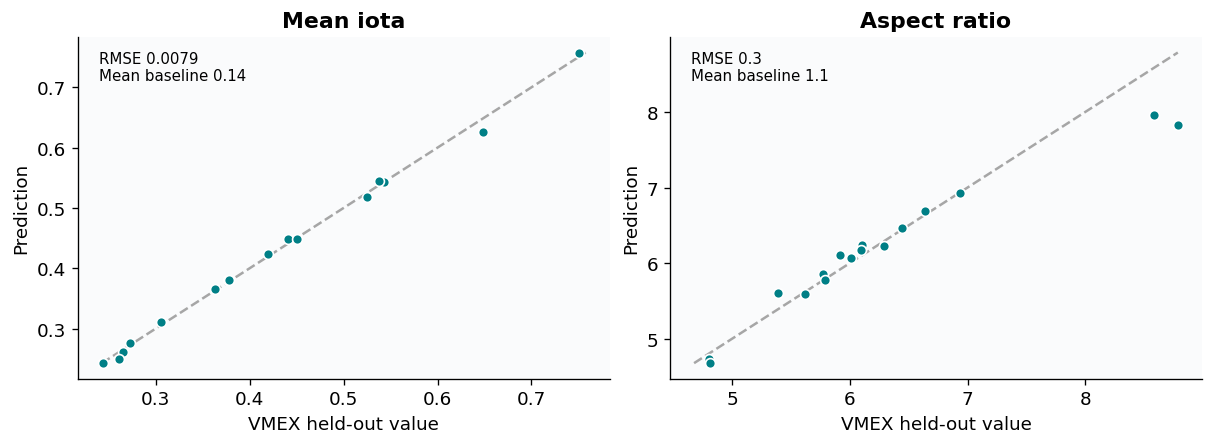

In [13]:
test = np.zeros(len(X), dtype=bool)
test[1+np.random.default_rng(RANDOM_SEED).permutation(len(X)-1)[:len(X)//4]] = True
train = valid & ~test
test &= valid
center, scale = Y[train].mean(axis=0), Y[train].std(axis=0)
scale = np.maximum(scale, 1e-12)
surrogate = RBFInterpolator(X[train], (Y[train]-center)/scale, smoothing=1e-6)
prediction = center+scale*surrogate(X[test])
show_predictions(Y[test], prediction, center)

Ask the surrogate for a promising boundary, then evaluate it with VMEX. Model accuracy on held-out rows does not guarantee accuracy at the point chosen by an optimizer. Keep the seed if the verified proposal is worse.

In [14]:
def score(labels):
    """Apply the same target loss to predicted or independently solved labels."""
    return 0.5*np.sum(((np.asarray(labels)[..., :2]-TARGETS)/SCALES)**2, axis=-1)


candidates = 2*qmc.Sobol(len(DOF_NAMES), scramble=True, seed=RANDOM_SEED+1).random_base2(12)-1
proposed_x = candidates[np.argmin(score(center+scale*surrogate(candidates)))]
proposal_y, proposal_error = observe(proposed_x)
if proposal_error:
    print("Proposal failed:", proposal_error)
print(f"True loss: {score(Y[0]):.6f} → {score(proposal_y):.6f}")
selected_x = proposed_x if score(proposal_y) < score(Y[0]) else np.zeros(len(DOF_NAMES))

True loss: 2.189853 → 0.001699


The four columns are `mean_iota`, `aspect_ratio`, `qs_qa_total`, and `magnetic_well`. Keep their definitions and the original boundary with the data: changing a label's surface selection or resolution changes the learning problem.

In [15]:
seed.to_json(OUTPUT / "seed_input.json")
np.savez(OUTPUT / "local_database.npz", X=X, Y=Y, valid=valid, errors=errors,
         train=train, test=test, label_names=LABEL_NAMES, dof_names=DOF_NAMES, step=STEP, targets=TARGETS, scales=SCALES,
         seed_json=(OUTPUT / "seed_input.json").read_text(), ns=NS, mpol=MPOL, ntor=NTOR, ftol=FTOL)
print("Saved the local database. X contains normalized shape inputs; Y contains physical labels.")

Saved the local database. X contains normalized shape inputs; Y contains physical labels.


### Sequential acquisition: let the optimizer request data

Random proposals waste the surrogate's smoothness. Minimize its predicted loss from several starts, verify the best proposal with VMEX, and add that result to the training set. Repeat with the **original test set untouched**. This is an exploitation-only acquisition rule; an uncertainty-aware ensemble is a useful replacement when evaluations are expensive.

The model can be confidently wrong at its predicted optimum. Compare predicted and observed losses each round, and retain the best *observed* design.

In [16]:
def propose(surrogate, center, scale):
    """Minimize predicted loss from several promising points in the box."""
    def predicted_loss(x):
        return float(score(center+scale*surrogate(np.atleast_2d(x)))[0])
    starts = candidates[np.argsort(score(center+scale*surrogate(candidates)))[:MULTISTART]]
    fits = [minimize(predicted_loss, x, method="L-BFGS-B", bounds=[(-1, 1)]*len(x)) for x in starts]
    best = min(fits, key=lambda fit: fit.fun)
    return best.x, best.fun

In [17]:
active_X, active_Y = X[train].copy(), Y[train].copy()
pool_X, pool_Y = np.vstack([active_X, proposed_x]), np.vstack([active_Y, proposal_y])
incumbent_x = pool_X[np.nanargmin(score(pool_Y))]
acquisition_errors = []
acquisitions, observed = [], [float(np.nanmin(score(pool_Y)))]
for round_index in range(ACTIVE_ROUNDS):
    center, scale = active_Y.mean(0), np.maximum(active_Y.std(0), 1e-12)
    surrogate = RBFInterpolator(active_X, (active_Y-center)/scale, smoothing=1e-6)
    candidate, predicted = propose(surrogate, center, scale)
    labels, error = observe(candidate)
    acquisition_errors.append(error)
    acquisitions.append(candidate); observed.append(float(score(labels)))
    if error:
        print("Acquisition failed:", error)
        continue
    active_X = np.vstack([active_X, candidate]); active_Y = np.vstack([active_Y, labels])
    print(f"Round {round_index+1}: predicted {predicted:.4g}; observed {observed[-1]:.4g}")

Round 1: predicted 6.838e-16; observed 0.008854


Round 2: predicted 5.889e-15; observed 8.439e-05


Round 3: predicted 2.286e-14; observed 0.002151


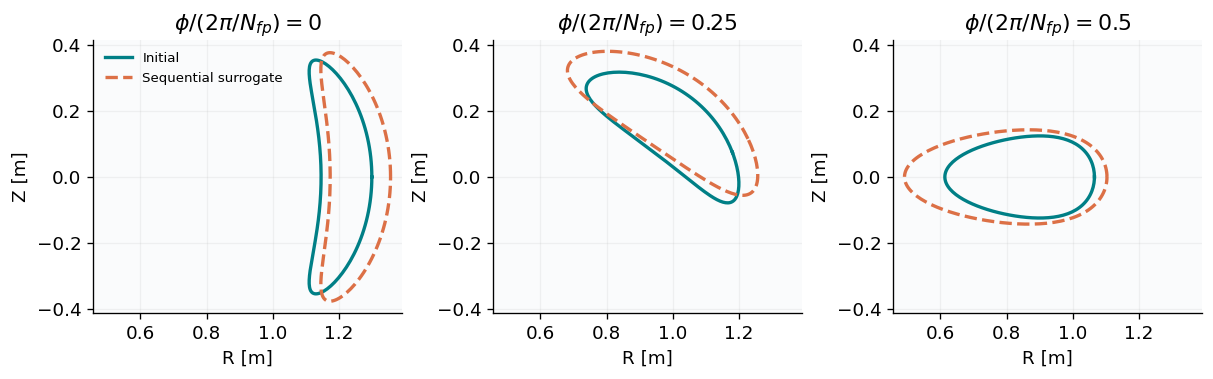

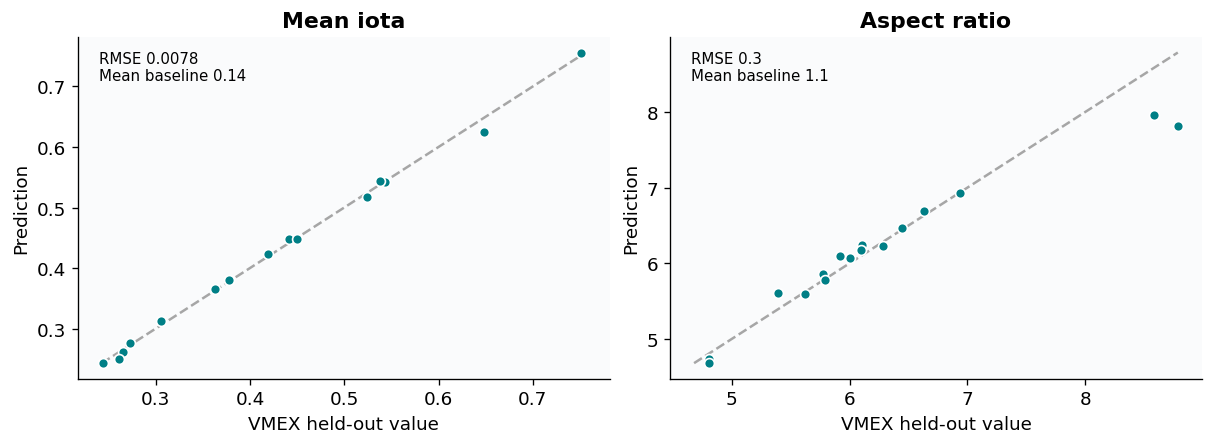

In [18]:
active_best = incumbent_x if np.nanargmin(observed) == 0 else acquisitions[np.nanargmin(observed)-1]
show_sections([initial, solve(active_best)], ["Initial", "Sequential surrogate"])
center, scale = active_Y.mean(0), np.maximum(active_Y.std(0), 1e-12)
surrogate = RBFInterpolator(active_X, (active_Y-center)/scale, smoothing=1e-6)
show_predictions(Y[test], center+scale*surrogate(X[test]), center)
np.savez(OUTPUT / "acquisition.npz", X=active_X, Y=active_Y, losses=observed, proposals=acquisitions, errors=acquisition_errors)

## 2. Differentiate through the physics

Now use VMEX derivatives for the same six parameters and target loss. The core interface is ordinary JAX and Optax:

```python
value, gradient = jax.value_and_grad(loss)(x)
updates, optimizer_state = optimizer.update(gradient, optimizer_state, x)
x = jnp.clip(optax.apply_updates(x, updates), -1, 1)
```

The learned variables here are the shape coefficients themselves. There is no neural network to train. You can also put a network upstream of this loss, or use these gradients as labels for a surrogate.

If $u$ denotes the equilibrium state and $F(u,x)=0$ its discrete equations, the derivative follows from

$$
F_u\,du/dx=-F_x.
$$

For a scalar loss, an adjoint solve computes the gradient without storing the forward iteration history. The first call includes JAX compilation; later calls reuse it. This is a derivative of the discretized equilibrium, conditional on convergence and a well-defined local branch. Automatic differentiation does not remove spatial or quadrature error.

Below we check a directional derivative with independent solves, run Adam, then independently solve the initial and best boundaries at the original and a finer radial grid. The angular resolution is unchanged; this is a partial refinement check. Adam is used because its interface is familiar, not because it is the best optimizer for six parameters. L-BFGS-B and least-squares methods are useful comparisons.

In [19]:
def loss(x):
    """Normalized parameters → VMEX equilibrium → scalar loss."""
    return problem.jax_fun(x_seed+STEP*x)


value_and_grad = jax.value_and_grad(loss)
x = jnp.zeros(len(DOF_NAMES))
value, gradient = value_and_grad(x)
print(f"Initial loss: {float(value):.6f}")

Initial loss: 2.189708


Before training, compare the derivative with independently converged positive and negative perturbations. This is a local check of the discrete derivative. Smaller steps eventually reveal solver tolerance error; larger steps introduce finite-difference truncation error.

In [20]:
direction = np.asarray(gradient)/np.linalg.norm(gradient)
h = 0.0006
plus, minus = solve(h*direction), solve(-h*direction)
fd = (float(physical_loss(plus.state, plus.runtime))
      - float(physical_loss(minus.state, minus.runtime)))/(2*h)
ad = float(gradient @ direction)
print(f"Directional derivative: AD {ad:.7f}; FD {fd:.7f}; relative error {abs(ad/fd-1):.2g}")
np.testing.assert_allclose(ad, fd, rtol=1e-3, atol=1e-6)

Directional derivative: AD 4.7112039; FD 4.7108577; relative error 7.3e-05


In [21]:
optimizer = optax.chain(optax.clip_by_global_norm(1.0), optax.adam(LEARNING_RATE))
optimizer_state = optimizer.init(x)
xs, losses = [], []
for iteration in range(ADAM_STEPS+1):
    value, gradient = value_and_grad(x)
    if not np.isfinite(value) or not np.isfinite(gradient).all():
        raise RuntimeError("Non-finite loss/gradient; inspect the equilibrium before continuing")
    xs.append(np.asarray(x)); losses.append(float(value))
    if iteration < ADAM_STEPS:
        updates, optimizer_state = optimizer.update(gradient, optimizer_state, x)
        x = jnp.clip(optax.apply_updates(x, updates), -1, 1)
best_x = xs[int(np.argmin(losses))]

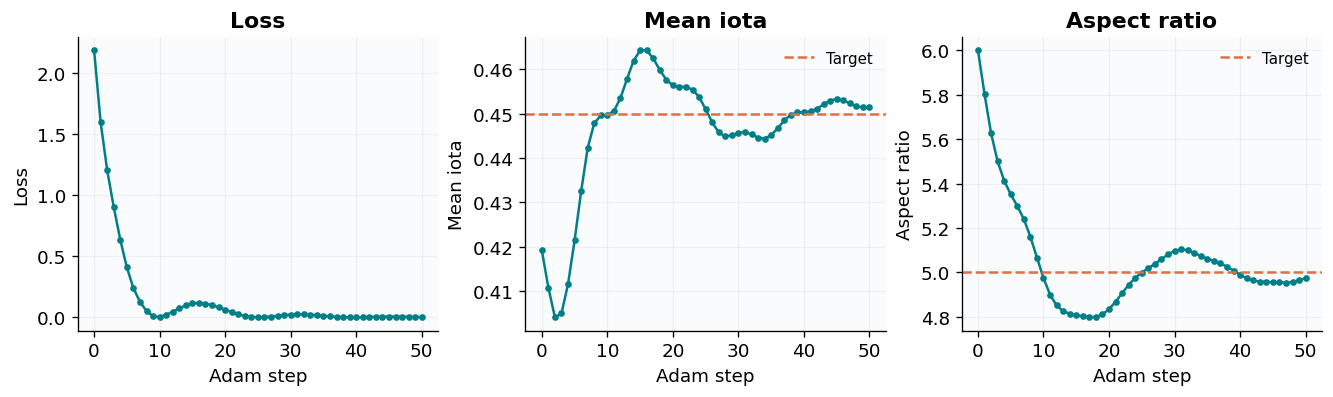

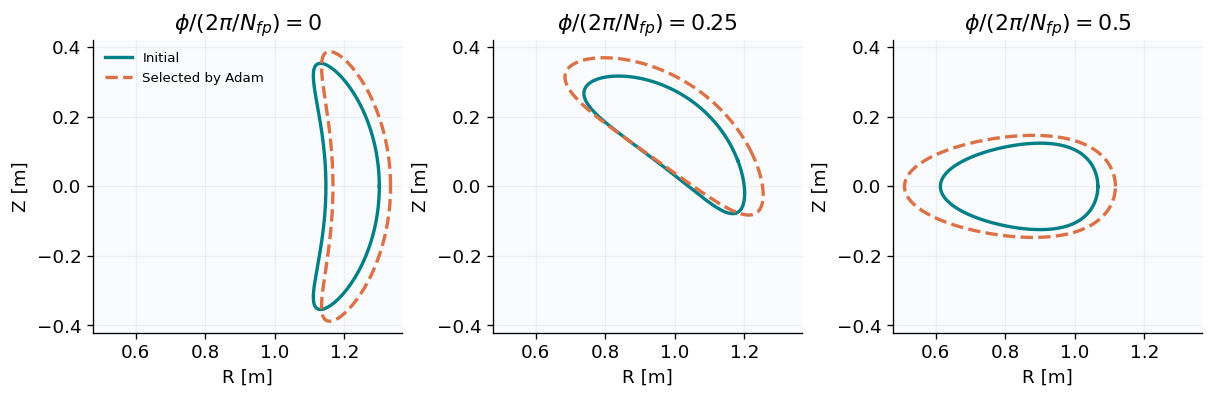

QA residual, initial → Adam: 8.091353020939342e-06 → 0.12509088834593463


In [22]:
# These physical labels come from independent solves, not the surrogate.
trajectory = [solve(x) for x in xs]
values = np.array([physical_labels(eq.state, eq.runtime) for eq in trajectory])
show_training(losses, values)
show_sections([initial, trajectory[int(np.argmin(losses))]], ["Initial", "Selected by Adam"])
print("QA residual, initial → Adam:", values[0, 2], "→", values[np.argmin(losses), 2])

Adam need not improve every step. We keep its best evaluated point and check both endpoints on a finer radial grid. Angular resolution is unchanged here; increase it too before interpreting a small gain as a physical improvement. The two routes have different evaluation budgets, so these results are not an optimizer ranking.

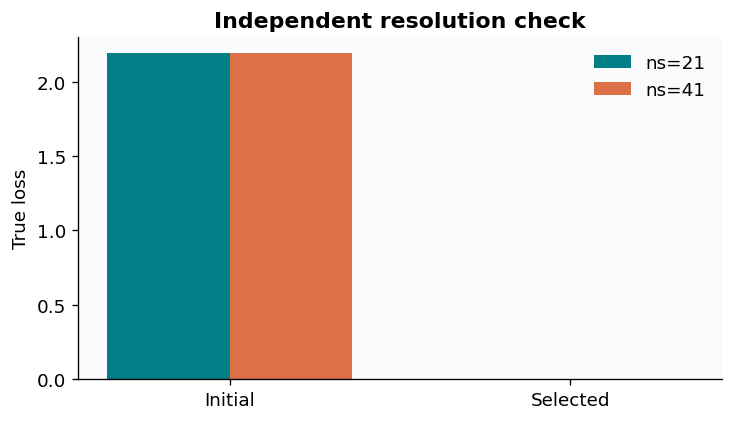

Independently solved losses: [2.1898529296436577, 0.00015683302405079875]
Refined-grid losses: [2.1897774968314137, 0.00014636401705162992]


In [23]:
coarse, refined = [], []
for x in (np.zeros(len(DOF_NAMES)), best_x):
    for ns, results in ((NS, coarse), (2*NS-1, refined)):
        eq = solve(x, ns=ns)
        results.append(float(physical_loss(eq.state, eq.runtime)))
show_verification(coarse, refined)
print("Independently solved losses:", coarse)
print("Refined-grid losses:", refined)

### A curvature-based optimizer on the same problem

For a small, smooth parameter vector, L-BFGS-B can use gradients more efficiently than Adam. Start from the same boundary and keep the same bounds. Its line search may evaluate several equilibria per iteration, so iteration counts alone are not a fair cost comparison.

CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL (9 value/gradient evaluations)
Refined iota 0.44988; aspect 5.00000; QA residual 1.1586


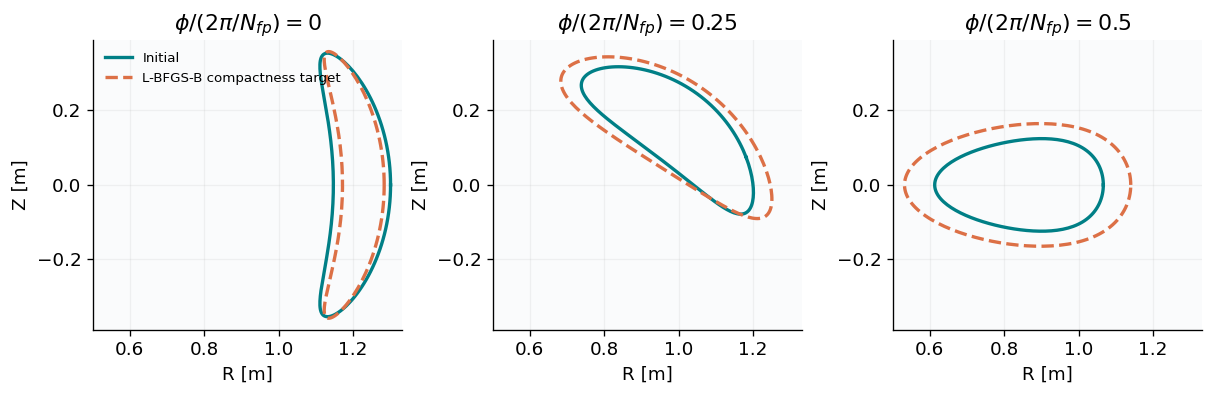

In [24]:
def scipy_value_grad(x):
    value, grad = value_and_grad(jnp.asarray(x))
    return float(value), np.asarray(grad)

lbfgs = minimize(scipy_value_grad, np.zeros(len(DOF_NAMES)), jac=True, method="L-BFGS-B",
                 bounds=[(-1, 1)]*len(DOF_NAMES), options={"maxiter": LBFGS_STEPS, "ftol": 1e-12})
compact = solve(lbfgs.x, ns=2*NS-1)
compact_labels = np.asarray(physical_labels(compact.state, compact.runtime))
print(lbfgs.message, f"({lbfgs.nfev} value/gradient evaluations)")
print(f"Refined iota {compact_labels[0]:.5f}; aspect {compact_labels[1]:.5f}; QA residual {compact_labels[2]:.5g}")
show_sections([initial, compact], ["Initial", "L-BFGS-B compactness target"])

The full-torus views show how much the tube thickens. Both use VMEX's standard camera. Colors show field strength in tesla on the outermost half-mesh surface; each panel has its own labeled color scale.

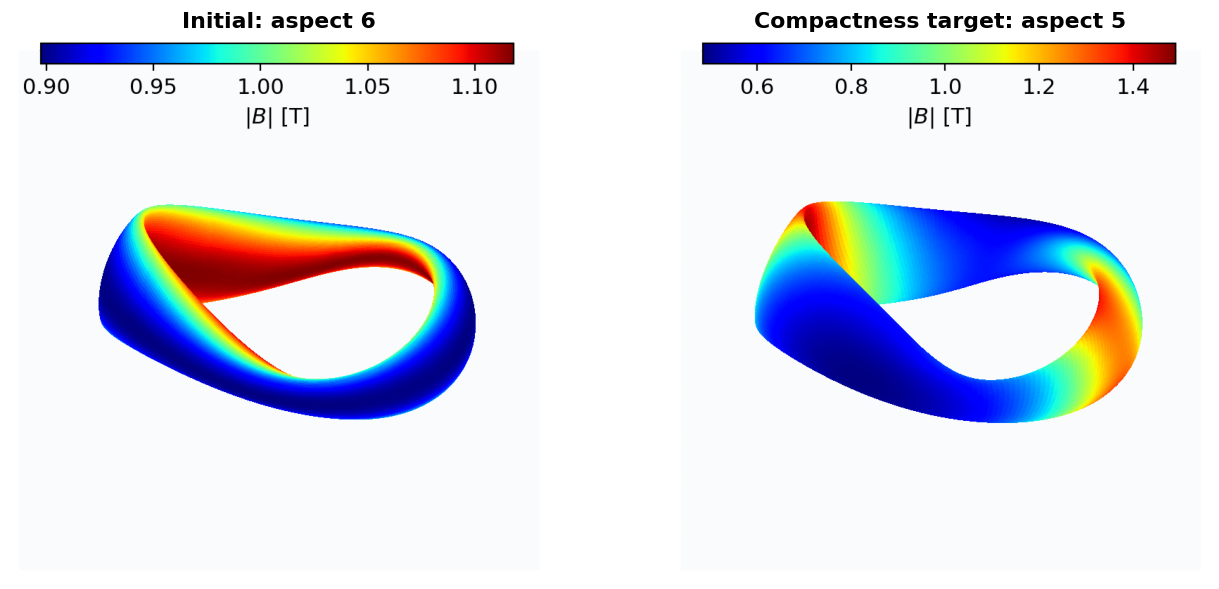

In [25]:
show_3d_pair([initial, compact], ["Initial: aspect 6", "Compactness target: aspect 5"], "compactness_3d")

The shape target is deliberately incomplete. A design can meet the iota and aspect targets while losing the seed's excellent quasisymmetry. The reported QA residual reveals this failure. A confinement objective must be present during optimization if we want to preserve or improve it. Next we solve that different problem from a simple, visibly different starting shape.

## 3. Build a quasi-axisymmetric configuration from a simple seed

The earlier experiment explored a restricted six-parameter family around an already optimized boundary. Now start with a rotating ellipse and **optimize the shape itself**. The major-radius coefficient and toroidal flux remain fixed. The boundary has 8 free Fourier coefficients in the first stage and 24 in the second, so the optimizer can discover substantial nonaxisymmetric shaping.

We seek aspect ratio 6, minimum $|\iota|$ above 0.42, and a smaller quasi-axisymmetry (QA) residual. A 0.01 margin on the iota penalty helps keep its independently verified minimum above the requested floor. This is a soft penalty, so we still check the result. The magnetic well is a reported output, with no well constraint in this experiment.

The objective uses the seed QA total $Q_0$ to set its scale:

$$
\mathcal L=\frac12\left[\frac{Q}{Q_0}+\left(\frac{A-6}{0.2}\right)^2+
\left(\frac{\max(0.43-\min_s|\iota(s)|,0)}{0.02}\right)^2\right].
$$

This measured run takes about a minute on the development machine, including independent and refined-grid verification. Compilation and hardware change the timing. The iteration budgets below are deliberate ceilings, not convergence claims.

In [26]:
QA_MODES, QA_BUDGETS = (1, 2), (12, 20)
QA_ASPECT, QA_IOTA_FLOOR, QA_IOTA_MARGIN = 6.0, 0.42, 0.01
QA_ASPECT_SCALE, QA_IOTA_SCALE = 0.2, 0.02
QA_SURFACES = np.linspace(0.1, 1.0, 10)
qa_seed = vj.VmecInput.from_file(REPO / "examples/data/input.minimal_seed_nfp2")
rbc, zbs = qa_seed.rbc.copy(), qa_seed.zbs.copy()
rbc[qa_seed.ntor-1, 1], zbs[qa_seed.ntor-1, 1] = -0.05, 0.05
qa_seed = replace(qa_seed, rbc=rbc, zbs=zbs, pres_scale=0., ncurr=1, curtor=0.,
                  ac=np.zeros_like(qa_seed.ac), lfreeb=False, delt=0.5,
                  ns_array=np.array([21]), ftol_array=np.array([1e-12]),
                  niter_array=np.array([5000]))
qa_seed = qa_seed.change_resolution(mpol=5, ntor=5, ntheta=16, nzeta=14)
qa_initial = opt.solve_equilibrium(qa_seed, raise_on_max_iterations=True)

{'QA total': np.float64(0.03873213278891482), 'Aspect': np.float64(11.546235660405177), 'Min |iota|': np.float64(0.3972540019771014), 'Mean iota': np.float64(-0.3985019579960168), 'Magnetic well': np.float64(-0.0059136265771050885)}


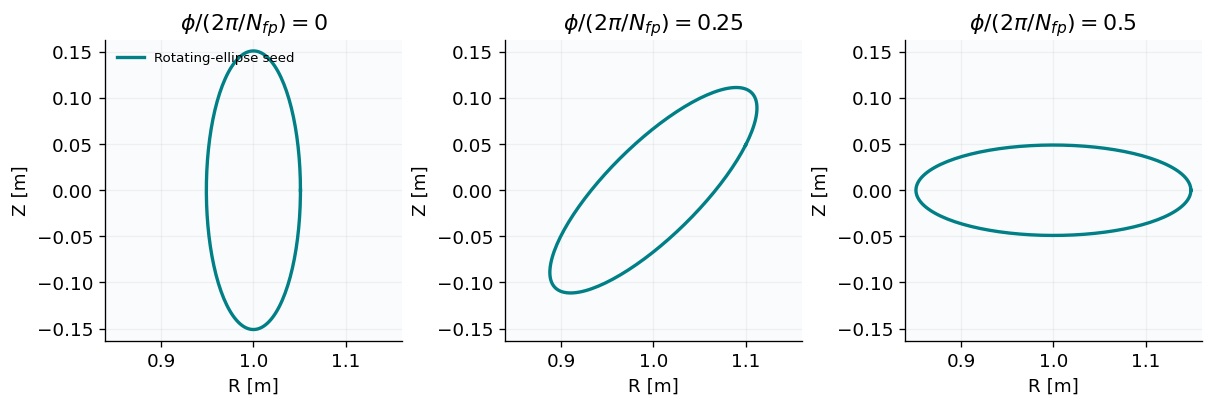

In [27]:
qa_qs = opt.QuasisymmetryRatioResidual(QA_SURFACES, helicity_m=1, helicity_n=0)
QA_NAMES = ["QA total", "Aspect", "Min |iota|", "Mean iota", "Magnetic well"]

def qa_metrics(eq):
    return np.array([float(f(eq.solution, eq.solver_context)) for f in
                     (qa_qs.total_state, opt.aspect_ratio, opt.min_abs_iota,
                      opt.mean_iota, opt.magnetic_well)])

qa_seed_values = qa_metrics(qa_initial)
print(dict(zip(QA_NAMES, qa_seed_values)))
show_sections([qa_initial], ["Rotating-ellipse seed"])

SciPy sees an ordinary residual vector and its Jacobian. VMEX handles the equilibrium solve and implicit differentiation inside those functions. The QA object contributes all its sampled residual rows; aspect and the iota hinge contribute one row each. We hold the highest modes fixed during the first stage and release them in the second. Both stages share the compiled physics problem.

In [28]:
qa_terms = [
    (qa_qs, 0., 1/qa_seed_values[0]),
    (opt.aspect_ratio, QA_ASPECT, 1/QA_ASPECT_SCALE**2),
    (opt.Hinge(opt.min_abs_iota, floor=QA_IOTA_FLOOR+QA_IOTA_MARGIN),
     0., 1/QA_IOTA_SCALE**2),
]
qa_problem = opt.VmecProblem.from_tuples(qa_seed, qa_terms, max_mode=max(QA_MODES),
                                        use_ess=True, restart_from=qa_initial, progress=True)
qa_x = qa_problem.x0
qa_history, qa_stages, qa_stops = [], [qa_seed_values], []

Building VMEX problem...


VMEX problem ready in 0.5 s.


In [29]:
for mode, budget in zip(QA_MODES, QA_BUDGETS):
    stage = qa_problem.subproblem(max_mode=mode, x=qa_x)
    step = 0.02*stage.scales  # metres; high Fourier modes receive smaller steps
    result = least_squares(stage.residual, stage.x0, jac=stage.residual_jac,
        x_scale=step, bounds=(stage.x0-5*step, stage.x0+5*step), max_nfev=budget,
        ftol=1e-7, xtol=1e-10, gtol=1e-7,
        callback=lambda intermediate_result: qa_history.append((mode, intermediate_result.cost)))
    qa_x = stage.embed(result.x)
    qa_final_input = qa_problem.input_from_x(qa_x)
    qa_current = qa_problem.equilibrium_from_x(qa_x)
    qa_stages.append(qa_metrics(qa_current))
    qa_stops.append(result.message)
    print(f"Mode {mode}, {stage.x0.size} coefficients: {dict(zip(QA_NAMES, qa_stages[-1]))}")
    print(result.message)

Mode 1, 8 coefficients: {'QA total': np.float64(0.018107096352885328), 'Aspect': np.float64(6.002442410173162), 'Min |iota|': np.float64(0.42868335722701967), 'Mean iota': np.float64(-0.445572419727582), 'Magnetic well': np.float64(-0.05080391594397664)}
The maximum number of function evaluations is exceeded.


Mode 2, 24 coefficients: {'QA total': np.float64(0.0002467841230546088), 'Aspect': np.float64(6.000069026019634), 'Min |iota|': np.float64(0.4299895952749909), 'Mean iota': np.float64(-0.4302402364403383), 'Magnetic well': np.float64(-0.08390424789286953)}
The maximum number of function evaluations is exceeded.


### Verify the configuration, then inspect what changed

Re-solve both endpoints independently. Then refine **both radial and angular resolution**: 21 to 41 radial points, Fourier resolution 5 to 7, angular grids $16\times14$ to $20\times18$, and force tolerance $10^{-12}$ to $10^{-13}$. This is one refinement check, not proof of full numerical convergence.

On the measured run the refined QA total falls from about $3.88\times10^{-2}$ to $2.34\times10^{-4}$, a factor of 166. Aspect changes from 11.55 to 6.00 and minimum $|\iota|$ from 0.397 to 0.429. Compare the values produced by your run, especially after changing a target or budget.

In [30]:
qa_independent, qa_refined, qa_verified = [], [], []
for candidate in (qa_seed, qa_final_input):
    cold = opt.solve_equilibrium(candidate, raise_on_max_iterations=True)
    finer_input = replace(candidate, ns_array=np.array([41]), ftol_array=np.array([1e-13]),
                          niter_array=np.array([8000]))
    finer_input = finer_input.change_resolution(mpol=7, ntor=7, ntheta=20, nzeta=18)
    finer = opt.solve_equilibrium(finer_input, raise_on_max_iterations=True)
    qa_independent.append(qa_metrics(cold))
    qa_refined.append(qa_metrics(finer))
    qa_verified.append(finer)
print("Columns:", QA_NAMES)
print("Independent seed/final:\n", np.array(qa_independent))
print("Refined seed/final:\n", np.array(qa_refined))

Columns: ['QA total', 'Aspect', 'Min |iota|', 'Mean iota', 'Magnetic well']
Independent seed/final:
 [[ 3.87321328e-02  1.15462357e+01  3.97254002e-01 -3.98501958e-01
  -5.91362658e-03]
 [ 2.45592066e-04  6.00006903e+00  4.29980864e-01 -4.30236604e-01
  -8.38998569e-02]]
Refined seed/final:
 [[ 3.87876939e-02  1.15462357e+01  3.96820213e-01 -3.98422411e-01
  -6.02328275e-03]
 [ 2.33818590e-04  6.00006903e+00  4.28844600e-01 -4.29813349e-01
  -8.42253750e-02]]


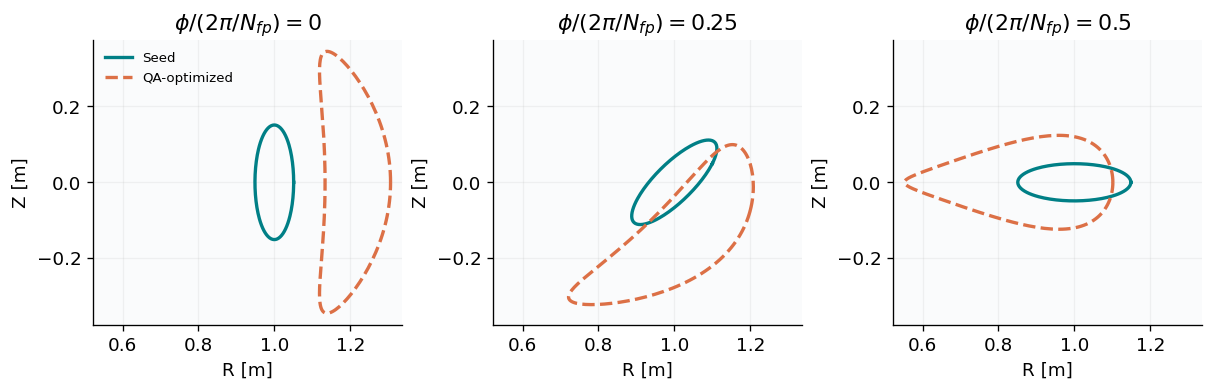

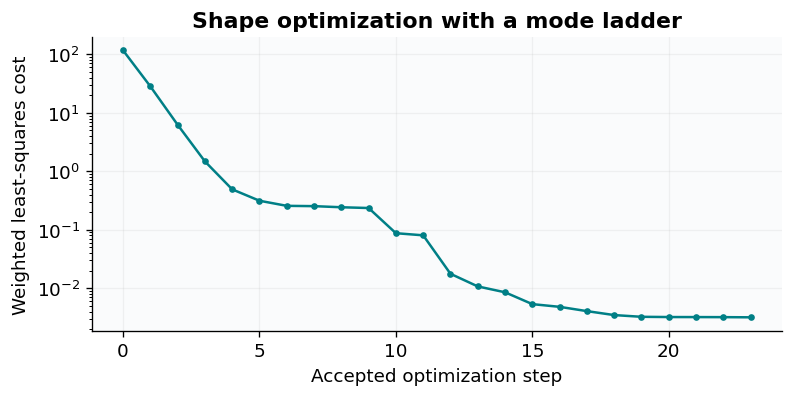

In [31]:
show_sections(qa_verified, ["Seed", "QA-optimized"])
fig, ax = plt.subplots(figsize=(6.5, 3.2), layout="constrained")
ax.semilogy(np.asarray(qa_history)[:, 1], color=TEAL, marker=".")
ax.set(xlabel="Accepted optimization step", ylabel="Weighted least-squares cost",
       title="Shape optimization with a mode ladder")
ax.grid(alpha=.15)
show_figure(fig)

Compare the complete configurations as well as their cross-sections. The larger tube and nonaxisymmetric shaping emerge from the optimization; the field colors alone do not measure quasisymmetry.

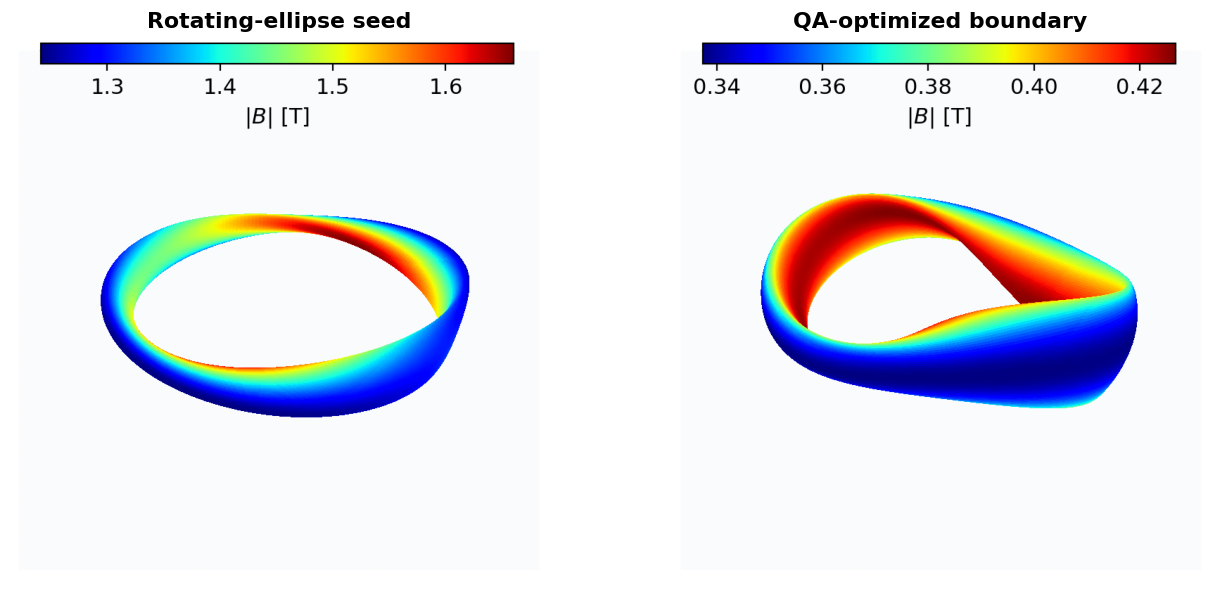

In [32]:
show_3d_pair(qa_verified, ["Rotating-ellipse seed", "QA-optimized boundary"], "qa_3d")

### Read the magnetic field in Boozer coordinates

For an exactly quasi-axisymmetric field, $|B|$ in Boozer coordinates is independent of the Boozer toroidal angle. Its contours are horizontal in the plots below. Both endpoints use the same refined resolution, the same nearest half-mesh surface, and the same color levels. Dividing by each field's $B_{00}$ makes the angular structure comparable as the cross-sectional area changes.

The plotting helper defined near the top calls the public Boozer transform and reconstructs field strength from its returned harmonics.

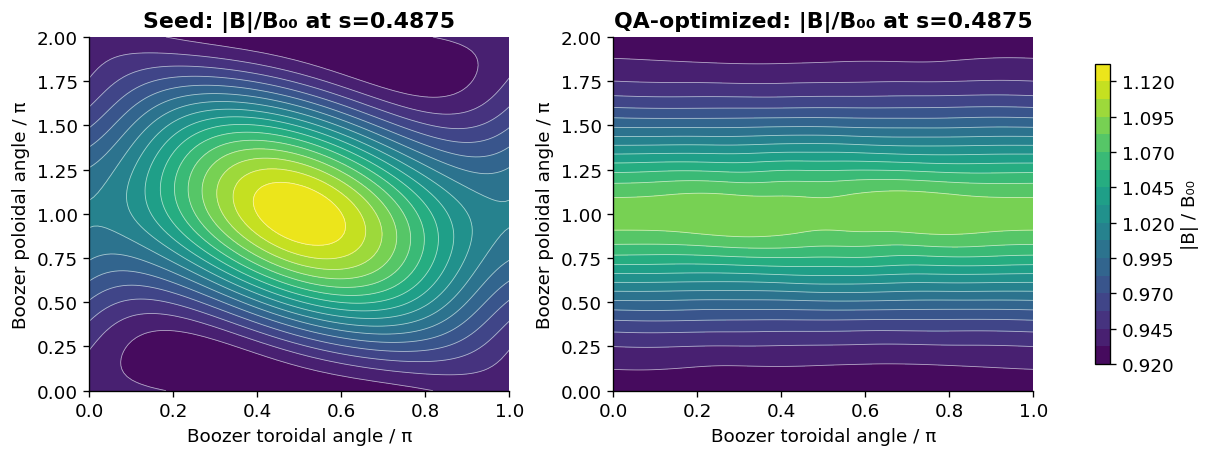

In [33]:
show_qa_boozer(qa_verified)
qa_final_input.to_json(OUTPUT / "qa_optimized_input.json")
np.savez(OUTPUT / "qa_optimization.npz", stages=qa_stages, independent=qa_independent,
         refined=qa_refined, history=qa_history, label_names=QA_NAMES, stop_messages=qa_stops)

**The tradeoff is real.** This objective does not constrain the magnetic well. In the measured refined calculation it changes from about $-0.006$ to $-0.084$ while QA and compactness improve. A better symmetry residual is not a universal improvement, and these boundaries have not been checked for coil realization, finite-pressure stability, or particle losses.

Try adding `(opt.Hinge(opt.magnetic_well, floor=0.0), 0.0, weight)` to `qa_terms`, then re-run this section. Compare the achieved QA, aspect, iota minimum and well, and verify the endpoint again. The weight encodes a design preference; a quadratic penalty does not guarantee that a limit is met.

## 4. Inspect the objective, not just the training curve

A decreasing training curve does not reveal the landscape around it. First take a straight path through Fourier-coefficient space, from each initial boundary to its optimized boundary:

$$c(t)=(1-t)c_{\mathrm{initial}}+t c_{\mathrm{final}},\qquad 0\leq t\leq1.$$

Each point below is a fresh equilibrium solve. These paths are not optimizer trajectories. Smooth behavior on a line does not establish global convexity, or rule out other basins in the full design space. The QA loss also contains a minimum over radial surfaces and a squared hinge; changes in the controlling surface can introduce kinks.

In [34]:
PATH_POINTS = 21
path_t = np.linspace(0, 1, PATH_POINTS)
path_losses = np.full((PATH_POINTS, 2), np.nan)
compact_input = problem.input_from_x(x_seed+STEP*lbfgs.x)
path_pairs = [(seed, compact_input), (qa_seed, qa_final_input)]
for j, (start, finish) in enumerate(path_pairs):
    for i, t in enumerate(path_t):
        inp = replace(start, rbc=(1-t)*start.rbc+t*finish.rbc, zbs=(1-t)*start.zbs+t*finish.zbs)
        eq = opt.solve_equilibrium(inp, raise_on_max_iterations=True)
        if j == 0:
            path_losses[i, j] = float(physical_loss(eq.state, eq.runtime))
        else:
            rows = opt.residuals_from_tuples(eq.state, eq.runtime, qa_terms)
            path_losses[i, j] = float(0.5*jnp.vdot(rows, rows))

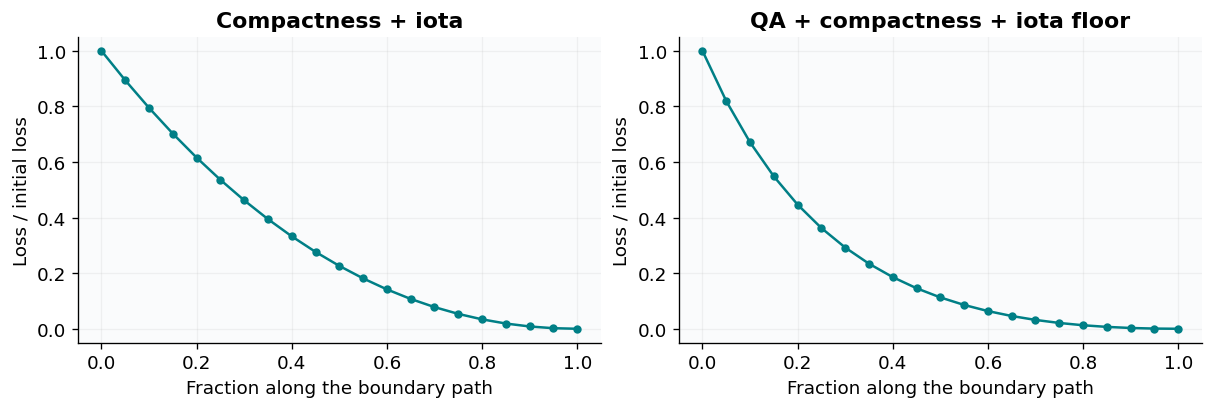

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
for j, (ax, title) in enumerate(zip(axes, ("Compactness + iota", "QA + compactness + iota floor"))):
    ax.plot(path_t, path_losses[:, j]/path_losses[0, j], "o-", color=TEAL, markersize=4)
    ax.set(xlabel="Fraction along the boundary path", ylabel="Loss / initial loss", title=title)
    ax.grid(alpha=.15)
show_figure(fig)
np.savez(OUTPUT / "objective_paths.npz", fraction=path_t, loss=path_losses)

Both 21-point paths decreased monotonically in the measured run; this does not exclude traps in other directions. The QA iota hinge stayed active along its entire path, and the controlling radial surface can still change. Compare each midpoint with a tighter solve to measure solver-tolerance effects relative to the sampled loss range. The earlier endpoint refinements separately test discretization effects.


In [36]:
path_mid, tight_losses = PATH_POINTS//2, []
for j, (a, b) in enumerate(path_pairs):
    t = path_t[path_mid]
    inp = replace(a, rbc=(1-t)*a.rbc+t*b.rbc, zbs=(1-t)*a.zbs+t*b.zbs, ftol_array=np.array([1e-14]), niter_array=np.array([10000]))
    eq = opt.solve_equilibrium(inp, raise_on_max_iterations=True)
    rows = opt.residuals_from_tuples(eq.state, eq.runtime, qa_terms) if j else None
    tight_losses.append(float(.5*jnp.vdot(rows, rows)) if j else float(physical_loss(eq.state, eq.runtime)))
relative_change = np.abs(tight_losses-path_losses[path_mid])/np.ptp(path_losses, axis=0)
print("Tight midpoint losses:", tight_losses, "; change / sampled loss range:", relative_change)
np.savez(OUTPUT / "objective_path_checks.npz", tight_midpoint=tight_losses, relative_change=relative_change)


Tight midpoint losses: [0.49525584364943753, 43.58120851414036] ; change / sampled loss range: [2.19575275e-05 9.82439384e-06]


## 5. A costly objective with competing basins

Now optimize a constructed-QI residual at **finite pressure**, starting from a bundled QI configuration. Pressure and toroidal flux remain fixed. We prescribe zero net toroidal-current profile; pressure-driven currents remain, as required by $\mathbf J\times\mathbf B=\nabla p$. The achieved beta is an output, not an additional trainable parameter.

To make the landscape visible, tie 24 boundary coefficients to one scalar $t$. At $t=1$ we have the original boundary; at $t=-1$ we have its toroidal reflection. Reflection preserves QI quality but reverses the sign of iota. A **signed** iota target distinguishes the two otherwise equivalent handedness choices. This is a controlled example of nonconvex *combined* optimization; it does not show that one handedness inherently confines particles better.

$$L(t)=\frac{Q_{\mathrm{QI}}(t)}{Q_{\mathrm{QI}}(1)}+0.05\left(\frac{\bar\iota(t)-\iota_*}{\iota_*}\right)^2,\qquad \iota_*=|\bar\iota(1)|.$$

Both local searches will use this same objective and the same bounds, $-1.2\leq t\leq1.2$. This remains a one-dimensional slice: a local minimum here need not be a local minimum when the other boundary directions are released. The QI calculation adds a Boozer transform and field-line/bounce-level sampling to every physics evaluation. This section takes several minutes and compiles another adjoint.

In [37]:
jax.clear_caches()  # Release compilation caches from the earlier experiments.
HARD_TARGET_BETA, HARD_PRESSURE_TRIAL = 0.01, 1e4
HARD_STARTS, HARD_BOUNDS, HARD_STEP, HARD_ITERATIONS = (0.9, -0.9), (-1.2, 1.2), 0.02, 40
HARD_SURFACES = (0.3, 0.5, 0.7)
HARD_QI = dict(mboz=8, nboz=8, oversample=1, nphi=41, nalpha=12, n_bounce=13, argmin_softness=0.02)
FINE_QI = dict(mboz=14, nboz=14, oversample=2, nphi=101, nalpha=29, n_bounce=31, argmin_softness=0.02)
hard_seed = vj.VmecInput.from_file(REPO / "examples/data/input.QI_nfp2_initial")
am = np.zeros_like(hard_seed.am); am[:2] = [1, -1]  # p(s) = pressure_scale * (1-s)
hard_seed = replace(hard_seed, am=am, pmass_type="power_series", pres_scale=HARD_PRESSURE_TRIAL,
    ncurr=1, curtor=0., ac=np.zeros_like(hard_seed.ac), lfreeb=False, delt=.5,
    ns_array=np.array([21]), ftol_array=np.array([1e-12]), niter_array=np.array([6000]))
hard_seed = hard_seed.change_resolution(mpol=5, ntor=5, ntheta=16, nzeta=14)

In [38]:
pressure_probe = opt.solve_equilibrium(hard_seed, raise_on_max_iterations=True)
beta_probe = float(opt.volume_average_beta(pressure_probe.state, pressure_probe.runtime))
hard_seed = replace(hard_seed, pres_scale=HARD_PRESSURE_TRIAL*HARD_TARGET_BETA/beta_probe,
                    ftol_array=np.array([1e-11]), niter_array=np.array([5000]))
hard_initial = opt.solve_equilibrium(hard_seed, raise_on_max_iterations=True)
hard_qi = ConstructedQIResidual(HARD_SURFACES, **HARD_QI)
fine_qi = ConstructedQIResidual(HARD_SURFACES, **FINE_QI)
qi_reference = float(hard_qi.total_state(hard_initial.state, hard_initial.runtime))
iota_reference = abs(float(opt.mean_iota(hard_initial.state, hard_initial.runtime)))
print(f"Seed beta: {float(opt.volume_average_beta(hard_initial.state, hard_initial.runtime)):.3%}")

Seed beta: 1.003%


The one-step pressure calibration puts the seed near 1% beta. Reshaping can change beta at fixed pressure and flux, so we report it again at the endpoints. The QI construction uses a soft minimum with width 0.02 of each surface's sampled field-strength modulation. This removes the hard grid-argmin jump; interpolation and running maxima can still produce kinks. Softening also changes the construction's endpoint treatment, so its loss is not interchangeable with the default hard-minimum residual.

In [39]:
reflected_r, reflected_z = hard_seed.rbc[::-1].copy(), hard_seed.zbs[::-1].copy()
# m=0 has redundant +/-n modes: preserve the canonical cosine/sine conventions.
reflected_r[:, 0], reflected_z[:, 0] = hard_seed.rbc[:, 0], -hard_seed.zbs[:, 0]
reflected = replace(hard_seed, rbc=reflected_r, zbs=reflected_z)
x_original, x_reflected = opt.pack_boundary(hard_seed, 2), opt.pack_boundary(reflected, 2)
hard_center, hard_direction = (x_original+x_reflected)/2, (x_original-x_reflected)/2


def hard_input(t, tolerance=1e-11):
    inp = opt.unpack_boundary(hard_seed, hard_center+float(t)*hard_direction, 2)
    return replace(inp, ftol_array=np.array([tolerance]), niter_array=np.array([10000]))

In [40]:
def hard_loss(state, runtime):
    iota = opt.mean_iota(state, runtime)
    return hard_qi.total_state(state, runtime)/qi_reference + 0.05*((iota-iota_reference)/iota_reference)**2


def hard_observe(t, tolerance=1e-13):
    """Independent solve; return coarse/fine QI losses, iota, beta and well."""
    eq = opt.solve_equilibrium(hard_input(t, tolerance), raise_on_max_iterations=True)
    iota = float(opt.mean_iota(eq.state, eq.runtime))
    penalty = 0.05*((iota-iota_reference)/iota_reference)**2
    losses = [float(q.total_state(eq.state, eq.runtime))/qi_reference+penalty for q in (hard_qi, fine_qi)]
    return np.array([*losses, iota, float(opt.volume_average_beta(eq.state, eq.runtime)),
                     float(opt.magnetic_well(eq.state, eq.runtime))])

### Scan before trusting the optimizer

Sample both valley brackets. The central interval is largely untested; any failed solve at $t=0$ is retained as missing data, not replaced by a large objective. A gap in the plot therefore does not represent a measured infinite barrier. We use the original QI normalization for both diagnostic grids so a change in scale cannot hide disagreement.

In [41]:
hard_t = np.r_[np.linspace(-1.2, -0.6, 13), 0., np.linspace(0.6, 1.2, 13)]
hard_values, hard_errors, hard_seconds = np.full((len(hard_t), 5), np.nan), [""]*len(hard_t), []
for i, t in enumerate(hard_t):
    tick = perf_counter()
    try:
        hard_values[i] = hard_observe(t, tolerance=1e-11)
    except (vj.VmecError, RuntimeError, ValueError) as error:
        hard_errors[i] = str(error)
    hard_seconds.append(perf_counter()-tick)
print(f"Converged scan points: {np.isfinite(hard_values[:, 0]).sum()}/{len(hard_t)}")
print(f"Median scan cost (equilibrium + two QI grids): {np.median(hard_seconds):.2f} s")

Converged scan points: 26/27
Median scan cost (equilibrium + two QI grids): 1.41 s


### Two starts, one gradient-based optimizer

Scale the optimizer coordinate as $t=0.02y$ to keep trial steps local on this narrow landscape. Both starts retain the full common bounds. The callback records accepted steps; a separate counter records all value/gradient evaluations, including rejected line-search trials. Cold starts prevent a previous branch's equilibrium from becoming the next branch's initial guess.

In [42]:
hard_problem = opt.VmecProblem.from_loss(hard_seed, hard_loss, max_mode=2, use_ess=False,
                                         hot_restart=False, warm_start=None, progress=True)
hard_evaluations, hard_accepted, hard_results, hard_fit_seconds = [], [], [], []


def hard_value_grad(y):
    tick = perf_counter()
    t = float(HARD_STEP*y[0])
    value, grad = hard_problem.value_and_grad(hard_center+t*hard_direction)
    derivative = float(grad @ hard_direction)
    hard_evaluations.append((hard_run, t, float(value), derivative, perf_counter()-tick))
    return float(value), np.array([HARD_STEP*derivative])

Building VMEX problem...


VMEX problem ready in 2.2 s.


In [43]:
hard_run, derivative_point = 0, HARD_STARTS[0]
tick = perf_counter()
_, scaled_gradient = hard_value_grad([derivative_point/HARD_STEP])
print(f"First QI value/gradient call: {perf_counter()-tick:.1f} s (includes compilation)")
for h in (0.00001, 0.0003, 0.001):
    fd = (hard_observe(derivative_point+h, 1e-16)[0]-hard_observe(derivative_point-h, 1e-16)[0])/(2*h)
    print(f"h={h:g}: implicit dL/dt {scaled_gradient[0]/HARD_STEP:.5g}; independent FD {fd:.5g}")

First QI value/gradient call: 24.5 s (includes compilation)


h=1e-05: implicit dL/dt -23.139; independent FD -21.585


h=0.0003: implicit dL/dt -23.139; independent FD -21.6


h=0.001: implicit dL/dt -23.139; independent FD -21.78


**This derivative check does not pass.** The implicit derivative is about −23.14, while independent finite differences approach −21.58 as the step shrinks. The discrepancy is roughly 7%; a smaller step does not remove it. Its cause has not been isolated, so it should not be attributed solely to physical ruggedness or to a particular numerical component.

We keep this as a diagnostic experiment. The optimizer can still make progress, but its gradient and stopping message do not certify a minimum of the independently evaluated objective. The cold-solve probes below are essential. This contrasts with the successful mean-iota/aspect derivative check earlier.

In [44]:
for hard_run, start in enumerate(HARD_STARTS):
    def accept(intermediate_result):
        hard_accepted.append((hard_run, float(HARD_STEP*intermediate_result.x[0]), float(intermediate_result.fun)))
    tick = perf_counter()
    fit = minimize(hard_value_grad, [start/HARD_STEP], jac=True, method="L-BFGS-B",
        bounds=[tuple(np.asarray(HARD_BOUNDS)/HARD_STEP)], callback=accept,
        options=dict(maxiter=HARD_ITERATIONS, ftol=1e-12, gtol=1e-7, maxls=25))
    hard_results.append(fit); hard_fit_seconds.append(perf_counter()-tick)
    print(f"Start {start:+.1f}: t={HARD_STEP*fit.x[0]:+.7f}, loss={fit.fun:.6f}, evaluations={fit.nfev}")
    print(fit.message)

Start +0.9: t=+1.0055843, loss=1.178057, evaluations=26
CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


Start -0.9: t=-1.0160716, loss=0.936106, evaluations=22
CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


### Check the stopping point, not just the stop message

Re-solve both selected boundaries independently. A small loss change can trigger `ftol` even when the gradient criterion is not met. Local probes and resolution checks are needed before calling such a point a minimum. The endpoint table reports the combined loss, signed mean iota, achieved beta and magnetic well.

In [45]:
hard_endpoints = np.array([HARD_STEP*fit.x[0] for fit in hard_results])
hard_verified = np.array([hard_observe(t, tolerance=1e-16) for t in hard_endpoints])
for start, t, fit, values in zip(HARD_STARTS, hard_endpoints, hard_results, hard_verified):
    derivative = float(fit.jac[0]/HARD_STEP)
    projected = abs(t-np.clip(t-derivative, *HARD_BOUNDS))
    print(f"Start {start:+.1f}: independent loss {values[0]:.6f}; finer QI {values[1]:.6f}; "
          f"iota {values[2]:+.5f}; beta {values[3]:.3%}; well {values[4]:+.5f}; projected gradient {projected:.2g}")

Start +0.9: independent loss 1.178452; finer QI 1.092181; iota -0.54981; beta 0.992%; well +0.00362; projected gradient 0.00012
Start -0.9: independent loss 0.935828; finer QI 0.857185; iota +0.55331; beta 0.971%; well +0.00364; projected gradient 3.5e-07


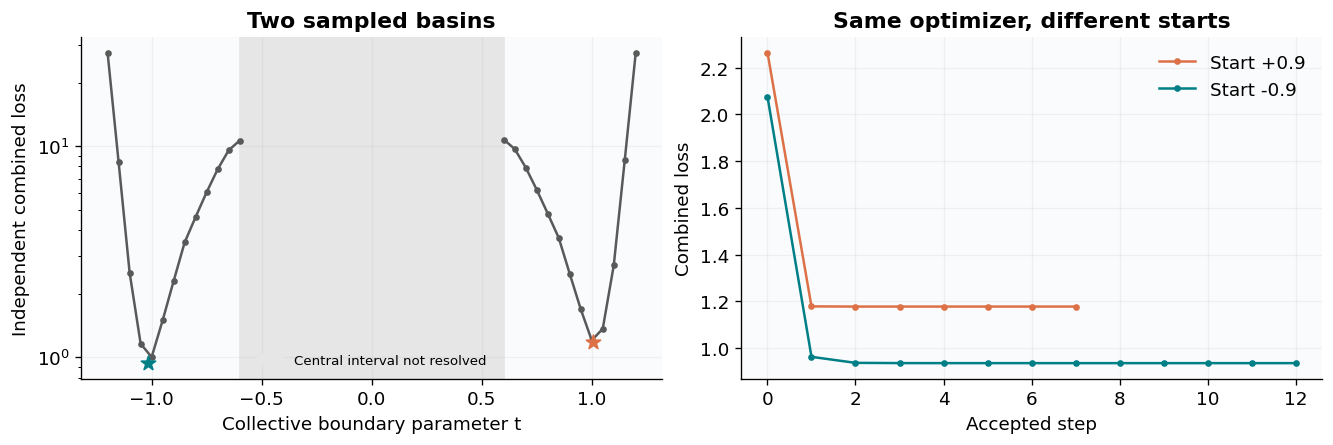

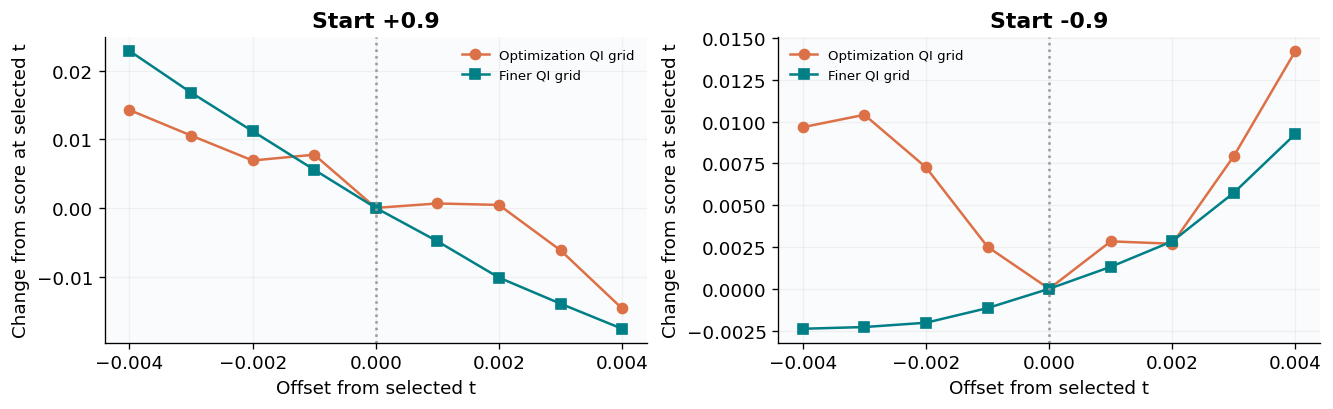

In [46]:
show_hard_search(hard_t, hard_values, hard_accepted, hard_endpoints, hard_verified)
probe_offsets = np.linspace(-0.004, 0.004, 9)
hard_local = np.array([[hard_observe(t+offset, tolerance=1e-16)[:2] for offset in probe_offsets] for t in hard_endpoints])
show_hard_refinement(probe_offsets, hard_local)
np.savez(OUTPUT / "finite_beta_qi.npz", t=hard_t, values=hard_values, errors=hard_errors,
         seconds=hard_seconds, evaluations=hard_evaluations, accepted=hard_accepted,
         endpoints=hard_endpoints, verified=hard_verified, offsets=probe_offsets, local=hard_local,
         qi_reference=qi_reference, iota_target=iota_reference, pressure=hard_seed.pres_scale)
_ = hard_seed.to_json(OUTPUT / "finite_beta_qi_seed.json")

### Locate the nearby minimum independently

The positive-start gradient run stops slightly before a nearby minimum. Use a bounded scalar search on **independent cold solves** to locate that minimum within a small bracket, then probe both sides. This is a verification step, not another gradient result. Finding a local minimum here while the other branch has lower loss gives a concrete example of why local progress does not establish global optimality.

In [47]:
def cold_qi_loss(t):
    eq = opt.solve_equilibrium(hard_input(t, 1e-16), raise_on_max_iterations=True)
    return float(hard_loss(eq.state, eq.runtime))


worse = hard_endpoints[np.argmax(hard_verified[:, 0])]
polished = minimize_scalar(cold_qi_loss, bounds=(worse-0.002, worse+0.002), method="bounded",
                           options=dict(xatol=1e-6, maxiter=16))
local_probe_t = polished.x+np.array([-0.0002, 0., 0.0002])
local_probe_loss = np.array([cold_qi_loss(t) for t in local_probe_t])
print(f"Independent local search: t={polished.x:.7f}, loss={polished.fun:.6f}; {polished.message}")
print("Left / center / right probe losses:", local_probe_loss)
np.savez(OUTPUT / "qi_local_minimum_check.npz", t=local_probe_t, loss=local_probe_loss)

Independent local search: t=1.0061146, loss=1.177810; Solution found.
Left / center / right probe losses: [1.17827646 1.17781048 1.17814589]


We also increase the equilibrium's angular resolution at both endpoints, keeping the same radial mesh and hence the same diagnostic surfaces. This checks the ordering of the two results; it is not a full radial convergence study.

In [48]:
hard_angular = []
for t in hard_endpoints:
    inp = hard_input(t, 1e-13).change_resolution(mpol=7, ntor=7, ntheta=20, nzeta=18)
    eq = opt.solve_equilibrium(inp, raise_on_max_iterations=True)
    penalty = 0.05*((float(opt.mean_iota(eq.state, eq.runtime))-iota_reference)/iota_reference)**2
    hard_angular.append([float(q.total_state(eq.state, eq.runtime))/qi_reference+penalty for q in (hard_qi, fine_qi)])
print("Angular-refined losses [optimization QI grid, finer QI grid]:\n", np.asarray(hard_angular))
np.savez(OUTPUT / "finite_beta_qi_refinement.npz", endpoints=hard_endpoints, losses=hard_angular)

Angular-refined losses [optimization QI grid, finer QI grid]:
 [[1.17189423 1.08581005]
 [0.92683439 0.84919886]]


In the measured run, the positive start stops in the higher valley (loss about 1.18), while the negative start reaches about 0.94. The positive run stops on `ftol` and fails an independent nearby-point test: it is a numerical stall in a worse basin, **not a certified local minimum**. The independent scalar check locates a nearby higher minimum at about $t=1.0061$, loss 1.178; the other branch is about 20% lower. The negative endpoint passes the small-neighborhood check on the optimization grid. Refining the QI grid changes the local slopes and the preferred stopping points. Read your run's derivatives and probes before interpreting either stop message.

These are two sampled feasible branches. The scan does not establish a smooth connecting barrier, and solver failure does not prove physical infeasibility.

The lower independently evaluated endpoint is a concrete counterexample to global optimality of the worse run **on this slice**. It is not a certificate that the lower endpoint is globally optimal, or that either is a minimum in the full 24-dimensional space. The signed-iota preference deliberately breaks reflection symmetry; without that preference, opposite handedness alone would not make one design better.

The finer QI curves also test a different failure mode: an optimizer can exploit details of a discretized construction. If a nearby point improves the refined score, the coarse stopping point is not a minimum of that refined objective. Refine the calculation and reoptimize before drawing conclusions about confinement. A positive well here is a reported geometric proxy, not a full finite-pressure stability calculation.

For larger studies, compare restarts, a surrogate-guided search, and local refinement under the same true-solve budget. [Panici et al., *Deflation Techniques for Stellarator Equilibrium and Optimization*](https://arxiv.org/abs/2602.09957) addresses systematic searches for distinct solutions. Effective ripple is another costly objective: [Unalmis et al.](https://arxiv.org/abs/2412.01724) demonstrates differentiable bounce averaging and finite-beta ripple optimization. VMEX's current WOUT-based ripple interface is useful for independent labels; this notebook uses its traceable QI construction for the gradient experiment.

A useful next experiment is symmetry-aware initialization: reflect the seed to match the desired iota sign before local refinement. Then release the tied coefficients through `hard_problem.value_and_grad` and check whether the minima persist in the full boundary space.

## Experiments worth trying

1. **Change the optimizer.** Keep the starting point, parameter bounds, loss, and evaluation budget fixed. Compare Adam with L-BFGS-B, a derivative-free method, or your optimizer. Report wall time, first-call compilation, physics evaluations, and independently verified final loss.
2. **Change the learner.** Replace the database response surface with a small network or ensemble. Compare against the existing baseline before adding capacity. Query VMEX where uncertainty is high or a candidate looks promising, then retrain.
3. **Change the physics objective.** Add a QA residual or a magnetic-well floor. For a floor, penalize only violations. QI and pwO are alternative design directions; a weighted sum of every available metric has no automatic physical justification.
4. **Try a larger design space.** Add Fourier coefficients gradually and reduce their allowed amplitude at higher mode number. Hold out whole starting configurations when measuring generalization. Fix scale and angle conventions before mixing databases.
5. **Check what the optimizer found.** Increase equilibrium and diagnostic resolution, repeat the gradient check over several perturbation sizes, inspect the iota profile, and evaluate confinement independently. A better coarse-grid loss can disappear on a finer grid.

These experiments do not optimize coils, island formation, finite-pressure stability, turbulence, or engineering limits. VMEX assumes nested flux surfaces. Treat these results as small numerical experiments, then add the physics needed for your research question.

## Data and code for larger studies

- [ConStellaration](https://arxiv.org/abs/2506.19583): QI-like boundary data and constrained optimization benchmarks, with [reference code](https://github.com/proximafusion/constellaration) and a [dataset](https://huggingface.co/datasets/proxima-fusion/constellaration). Preserve the release, coordinate conventions, pressure/current settings, and label definitions when comparing results.
- [QUASR](https://quasr.flatironinstitute.org/): quasisymmetric configurations and associated coils, useful when moving from boundary design to coil geometry.
- [BoSS](https://arxiv.org/abs/2610.37910): a 2026 preprint and [fast-ion simulation dataset](https://boss.flatironinstitute.org/), for questions that require particle information beyond equilibrium proxies.
- [DESC](https://github.com/PlasmaControl/DESC) and [SIMSOPT](https://github.com/hiddenSymmetries/simsopt): alternative equilibrium and optimization tools. Their data and objective normalizations are not interchangeable by name alone.

## A short reading path

- [Landreman & Paul (2022)](https://doi.org/10.1103/PhysRevLett.128.035001): the quasi-axisymmetric seed and why magnetic symmetry matters.
- [VMEX objective definitions](https://vmex.readthedocs.io/en/latest/reference/objectives.html): objective definitions, including conventions and limitations.
- [VMEX adjoint gradients](https://vmex.readthedocs.io/en/latest/explanation/adjoint-gradients.html): what the implicit derivative represents and how to check it.
- [Goodman et al. (2023)](https://arxiv.org/abs/2211.09829): constructing nearly quasi-isodynamic fields.
- [Velasco et al. (2024)](https://arxiv.org/abs/2405.07634): the definition of piecewise omnigenity; [Liu et al. (2026)](https://arxiv.org/abs/2603.12139) describes the mapped construction used here.
- [Velasco et al. (2021)](https://arxiv.org/abs/2106.05697): fast-ion proxies and their relationship to prompt losses; [Nemov et al. (1999)](https://doi.org/10.1063/1.873749) defines effective ripple.
- [Merlo et al.](https://arxiv.org/abs/2211.09743): a physics-regularized equilibrium surrogate. The ConStellaration paper above provides an ML benchmark.

Start by changing one target or replacing one optimizer, then check the result with VMEX.